# Declaración responsable sobre autoría y uso ético de inteligencia artificial, otros recursos o ayuda externa

Con la entrega de esta tarea, declaro de manera responsable que
es el resultado de mi trabajo intelectual personal y creativo, y que ha sido elaborado de acuerdo con los principios éticos y las normas de integridad vigentes en la comunidad académica y, más
específicamente, en la [Universidad Complutense de Madrid](https://www.ucm.es/file/declaracion-responsable-sobre-autoria-y-uso-%C3%89tico-de-herramientas-de-ia).

Soy, pues, autor del material aquí incluido y, cuando no ha sido así y he tomado el material de
otra fuente, lo he citado o bien he declarado su procedencia de forma clara -incluidas, en su
caso, herramientas de inteligencia artificial-. Las ideas y aportaciones principales incluidas en este trabajo, y que acreditan la adquisición de competencias, son mías y no proceden de otras fuentes o han sido reescritas usando material de otras fuentes.

Antes de entregar esta tarea, asegúrate de que todo funcione como se espera:

1. Reinicia el kernel  
   *(En la barra de menú, selecciona **Kernel → Restart**)*  

2. Ejecuta todas las celdas  
   *(En la barra de menú, selecciona **Cell → Run All**)*  

3. Asegúrate de completar todos los lugares donde aparezca:  
   - `YOUR CODE HERE`  
   - `"YOUR ANSWER HERE"`
     
4. Debes borrar las instrucciones que pone `raise NotImplementedError()`

5. Así como tu **nombre** a continuación:

In [1]:
NOMBRE = "JAIME RUIZ LÓPEZ-ALVARADO"

## Notas para la entrega

* Se deben rellenar todos los cuadernos sin cambiar el nombre.
* Es impor
* Se debe comprimir la carpeta `tarea_final` en un fichero `.zip`, llamado `tarea_final.zip`.
  
  **Importante**: por favor, no se entreguen ficheros `.rar`.

* Los ficheros CSV son bastante grandes y no son necesario incluirlos. Por eso es **importante** boorrarlos andes de generar el fichero comprimido.
* También es importante borrar los ficheros auxiliares como `*.ipynb_checkpoints`, `.mypy_cache`, `__pycache` y otros fiche.
* Subir el fichero comprimido al campus virtual.

# Ejercicio de Programación en Python: Análisis de Datos de Tráfico sin Pandas

En este cuaderno resolverás una serie de ejercicios prácticos para procesar y analizar un conjunto de datos real de multas de tráfico del Ayuntamiento de Madrid, utilizando únicamente la librería estándar de Python y estructuras de datos nativas (`dict`, `tuple`, `list`, `datetime`).

---

## Celda de Configuración: Importación de Módulos

Importa en la siguiente celda todos los módulos de la librería estándar necesarios para los ejercicios (incluyendo anotaciones de tipos y manejo de fechas con `datetime`). En este ejercicio analizaremos el fichero `2023_nov.csv` del que vemos las 10 primeras líneas.

In [2]:
with open('2023_nov.csv') as f:
    for _ in range(10):
        line = next(f).strip()
        print(line)

CALIFICACION;LUGAR;MES;ANIO;HORA;IMP_BOL;DESCUENTO; PUNTOS;DENUNCIANTE;HECHO-BOL;VEL_LIMITE;VEL_CIRCULA ;COORDENADA-X;COORDENADA-Y
LEVE      ;BRAVO MURILLO, 261                      ;11;2023;09.50;  60.00;SI;0;AGENTES DE MOVILIDAD          ;NO ADVERTIR LA MANIOBRAAL RESTO DE USUARIOS DE LA VÍA.                                                                       ;   ;   ;    4400.56;   44787.09
GRAVE     ;PEDRO RICO, 1                           ;11;2023;08.38; 200.00;SI;0;AGENTES DE MOVILIDAD          ;ESTACIONAR EN ZONA SEÑALIZADA PARA USO EXCLUSIVO DE PERSONAS CON MOVILIDAD REDUCIDA.                                         ;   ;   ;    4416.15;   44816.22
GRAVE     ;VELAZQUEZ, 80                           ;11;2023;11.33; 200.00;SI;3;AGENTES DE MOVILIDAD          ;CONDUCIR UTILIZANDO AURICULAR O DISPOSITIVO QUE DISMINUYA LA ATENCIÓN PERMANENTE A LA CONDUCCIÓN.                            ;   ;   ;    4419.77;   44753.77
LEVE      ;GERARDO CORDON, 53                      ;11;2023;11.27

Empezamos instalando un módulo que facilita la definición de tests. Los tests de este cuaderno están en el fichero `test_01.py`.
Si no lo tienes instalado, instálalo ahora descomentando y ejecutand la siguiente celda. Cuando lo hagas, comántala de nuevo para evitar fallos posteriores.

In [3]:
#%pip install pytest

In [4]:
# Imports
import pytest
import doctest
import os
import testing_01 as testing
import csv
import random
from datetime import datetime
from typing import TypedDict

# Constants
TESTDATAFILE = 'data_test.csv'
NOV_2023 = '2023_nov.csv'

MONTHS = ['jan', 'feb', 'mar', 'apr', 'may', 'jun',
          'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

QUALIFICATIONS = ('LEVE', 'GRAVE', 'MUY GRAVE')

# Data Structures 
class TrafficFine(TypedDict):
    date_time: datetime
    qualification: str
    location: str
    complainant: str
    amount: int
    speed_limit: int | None   # solo en multas de velocidad
    real_speed: int | None    # solo en multas de velocidad

class Counter(TypedDict):
    count: int
    total: int
    mean: float

## Ejercicio 1: Generación de Muestra Aleatoria

Cuando los ficheros de trabajo son grandes, conviene tener ficheros más pequeños para realizar pruebas más rápidas. Por ello vamos a realizar una función que realiza esa tarea.
Escribe una función con la cabecera 
```python
def generate_sample(input_filepath: str, percentage: int) -> None
``` 
que reciba la ruta de un fichero CSV y cree un nuevo fichero con una muestra aleatoria representativa del porcentaje indicado. El fichero generado debe conservar la cabecera original y llamarse `XXX_PP.csv` (donde `XXX` es el nombre base del fichero sin extensión y `PP` es el porcentaje entero formateado a 2 dígitos, por ejemplo `2023_nov_05.csv` para el 5%). El porcentaje es un un entero, el 5 indica que quiero el 5% de los datos. Se debe comprobar que el porcentaje es estrictamente mayor que 0 y estricatemente menor que 100.

In [5]:
def generate_sample(input_filepath: str, percentage: int) -> None:
    """
    Genera un fichero CSV con una muestra aleatoria de los registros de otro CSV.

    El fichero se recorre dos veces sin cargarlo entero en memoria: la primera para
    contar los registros y la segunda para escribir los elegidos. El fichero resultante se guarda en el mismo directorio 
    que el original con el nombre ``XXX_PP.csv``, donde ``XXX`` es el nombre base del
    fichero sin extensión y ``PP`` es el porcentaje con 2 dígitos
    (p. ej. ``2023_nov_05.csv`` para el 5 %).

    Args:
        input_filepath: Ruta del fichero CSV de entrada (UTF-8, con cabecera).
        percentage: Porcentaje entero de registros que se incluyen en la
            muestra. Debe cumplir 0 < percentage < 100.

    Returns:
        None. Escribe el fichero de muestra en disco.

    Raises:
        TypeError: Si ``percentage`` no es un entero (``bool`` no se acepta).
        ValueError: Si ``percentage`` no está en el intervalo (0, 100) o si
            el fichero está vacío.
        FileNotFoundError: Si ``input_filepath`` no existe.

    Example:
        >>> generate_sample("2023_nov.csv", 5)  # crea 2023_nov_05.csv
    """
    if isinstance(percentage, bool) or not isinstance(percentage, int):
        raise TypeError("El porcentaje debe ser un número entero.")
    
    if not 0 < percentage < 100:
        raise ValueError("El porcentaje debe ser estrictamente mayor que 0 y menor que 100.")

    directory, filename = os.path.split(input_filepath)
    base, _ = os.path.splitext(filename)
    output_filepath = os.path.join(directory, f"{base}_{percentage:02d}.csv")

    # Primera pasada: contar los registros (sin la cabecera)
    with open(input_filepath, newline="", encoding="utf-8") as f:
        reader = csv.reader(f)
        if next(reader, None) is None:
            raise ValueError("El fichero está vacío.")
        n_rows = sum(1 for _ in reader)

    # Elegir al azar qué registros forman la muestra
    k = round(n_rows * percentage / 100)
    selected = set(random.sample(range(n_rows), k))

    # Segunda pasada: escribir la cabecera y los registros elegidos
    with open(input_filepath, newline="", encoding="utf-8") as fin, \
         open(output_filepath, "w", newline="", encoding="utf-8") as fout:
        reader = csv.reader(fin)
        writer = csv.writer(fout)
        writer.writerow(next(reader))
        writer.writerows(row for i, row in enumerate(reader) if i in selected)

### Auto comprobación

La salida de la siguiente casilla debe ser similar a la siguiente.

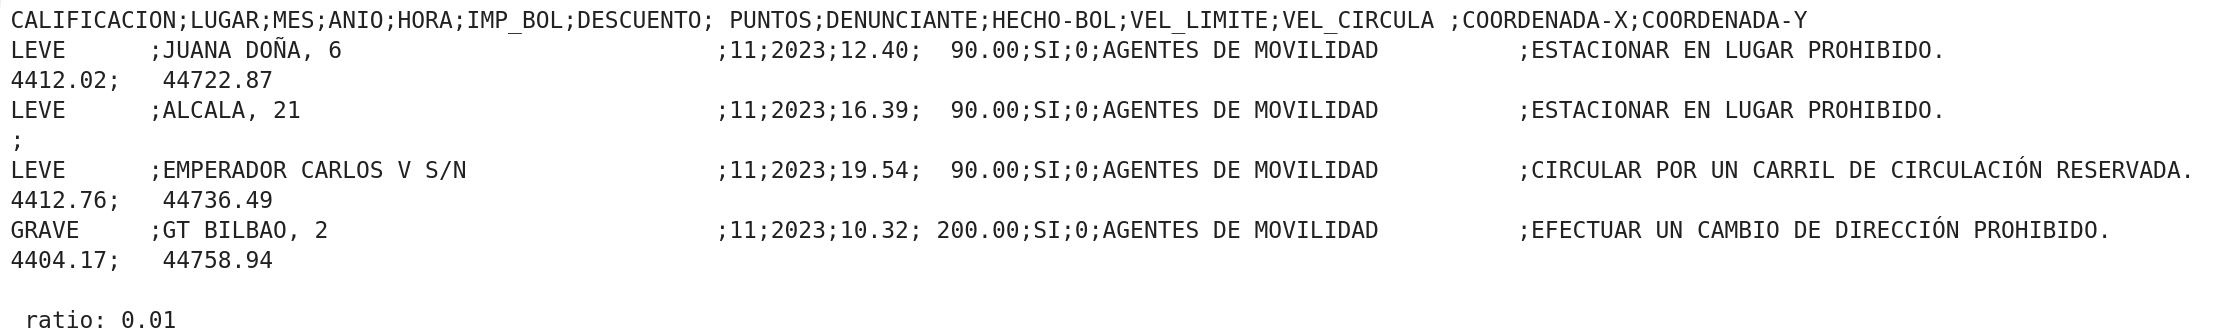

In [6]:
def check_gen_sample_result():
    generate_sample(NOV_2023, 1)
    data01 = NOV_2023.replace('.csv', '_01.csv')
    with open(data01, encoding='utf-8-sig') as f:
        for _ in range(5):
            print(f.readline(), end='')
    ratio = os.path.getsize(data01) / os.path.getsize(NOV_2023) 
    print(f'\n ratio: {ratio:0.2f}')
check_gen_sample_result()

CALIFICACION;LUGAR;MES;ANIO;HORA;IMP_BOL;DESCUENTO; PUNTOS;DENUNCIANTE;HECHO-BOL;VEL_LIMITE;VEL_CIRCULA ;COORDENADA-X;COORDENADA-Y                                                                                                                                          
LEVE      ;ARAPILES, 17                            ;11;2023;16.11;  90.00;SI;0;AGENTES DE MOVILIDAD          ;ESTACIONAR EN LUGAR PROHIBIDO.                                                                                               ;   ;   ;    4399.97;   44762.89
GRAVE     ;RAFAELA YBARRA-DOLORES BARRAN           ;11;2023;13.48; 200.00;SI;4;AGENTES DE MOVILIDAD          ;REBASAR UN SEMÁFORO EN FASE ROJA.                                                                                            ;   ;   ;           ;           
GRAVE     ;F 5244                                  ;11;2023;08.40; 200.00;SI;0;AGENTES DE MOVILIDAD          ;ESTACIONAR SOBRE LA ACERA OBSTACULIZANDO GRAVEMENTE EL TRÁNSITO DE PEATONES.         

Comprueba tus doctests

In [7]:
doctest.run_docstring_examples(generate_sample, globals(), verbose=True)

Finding tests in NoName
Trying:
    generate_sample("2023_nov.csv", 5)  # crea 2023_nov_05.csv
Expecting nothing
ok


Comprueba la calidad del docstring

In [8]:
help(generate_sample)

Help on function generate_sample in module __main__:

generate_sample(input_filepath: str, percentage: int) -> None
    Genera un fichero CSV con una muestra aleatoria de los registros de otro CSV.
    
    El fichero se recorre dos veces sin cargarlo entero en memoria: la primera para
    contar los registros y la segunda para escribir los elegidos. El fichero resultante se guarda en el mismo directorio 
    que el original con el nombre ``XXX_PP.csv``, donde ``XXX`` es el nombre base del
    fichero sin extensión y ``PP`` es el porcentaje con 2 dígitos
    (p. ej. ``2023_nov_05.csv`` para el 5 %).
    
    Args:
        input_filepath: Ruta del fichero CSV de entrada (UTF-8, con cabecera).
        percentage: Porcentaje entero de registros que se incluyen en la
            muestra. Debe cumplir 0 < percentage < 100.
    
    Returns:
        None. Escribe el fichero de muestra en disco.
    
    Raises:
        TypeError: Si ``percentage`` no es un entero (``bool`` no se acepta).
   

### Comprobación automática del código

In [9]:
testing.test_generate_sample(generate_sample)

test_gen_sample 1 1
Sample size 1 OK
test_gen_sample 2 1
Sample size 2 OK
test_gen_sample 5 1
Sample size 5 OK
test_gen_sample 10 1
Sample size 10 OK
check ratio values OK


In [10]:
testing.test_gen_sample_typehints(generate_sample)

check type hints OK


In [11]:
testing.test_docstring(generate_sample)

docstring OK


In [12]:
testing.test_doctests(generate_sample, globals())

doctests OK


## Ejercicio 2: Definición de TypedDict y Carga de Datos en Memoria

Define una clase `TrafficFine` que herede de `TypedDict` y especifique la estructura tipada de cada registro de multa en memoria (con las claves en inglés y minúsculas: 
`'date_time'` de tipo `datetime`, y `'qualification'`, `'location'`, `'complainant'` de tipo `str`,  `'amount'`, '`speed_limit`' y '`real_speed`' de tipo int). 
Ten en cuenta que el impoerte de la multa viene como un número real, en realidad son cantidades enteras.

Los datos de velocidad son solo para multas relacionadas con sobrepasar los límites de velocidad, por tanto deben see datos opcionales en `TrafficFine`

El fichero CSV real no tiene una columna `FECHA` con el día completo: solo dispone de `MES` (número de mes), `ANIO` y `HORA`, y no incluye el día del mes. Por eso, en lugar de leer el año y el mes de cada fila, estas dos funciones lo recibirán como parámetros y usaremos el día 1 del mes indicado para construir `date_time`.



Escribe dos funciones con las cabeceras
```python
def parse_row(row: dict[str, str], year: int, month: str) -> TrafficFine:
def load_fines_data(year: int, month: str, filepath: str|None=None,) -> list[TrafficFine]:
```
donde `month` es una cadena de 3 letras en inglés (`'jan'`, `'feb'`, ..., `'dec'`). Define una constante `MONTHS` (ya declarada en la celda de constantes) que sea una lista ordenada con esos 12 meses abreviados, y úsala para convertir `month` en el número de mes correspondiente. La función que lee las fechas tiene un tercer parámetro opcional. Si no se da, se lee el ficho que tiene como nombre `yyyy_mm.csv` donde `yyyy` es el año y `mm` es el mes. Si se da se lee el nombre del fichero indicado. 


`load_fines_data` debe usar `parse_row` internamente. La hora se combina con el año/mes/día (día = 1) para construir el objeto `datetime` de `'date_time'`.

Las columnas de texto del CSV (`CALIFICACION`, `LUGAR`, `DENUNCIANTE`) tienen espacios de relleno; `parse_row` debe guardarlas ya sin esos espacios sobrantes (`'qualification'`, `'location'` y `'complainant'` limpios), para que cualquier código que reutilice `TrafficFine` (incluidos otros cuadernos) no tenga que volver a limpiarlas.

**Restricción importante:** la carga de datos **no debe usar ningún bucle `for` o `while` explícito** (usa comprensiones de listas, `map` u otras herramientas nativas de Python).

In [13]:
def parse_row(row: dict[str, str], year: int, month: str) -> TrafficFine:
    """Convierte una fila del CSV en un TrafficFine.

    Como el CSV no trae el día, se usa el día 1 del mes indicado junto con
    la HORA de la fila. Los textos se guardan sin espacios de relleno y las
    velocidades vacías como None.

    Args:
        row: Fila leída con csv.DictReader.
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').

    Returns:
        TrafficFine: La multa con los datos ya limpios.

    Raises:
        ValueError: Si `month` no está en MONTHS.

    Examples:
        >>> row = {'CALIFICACION': 'GRAVE  ', 'LUGAR': 'CALLE MAYOR  ', 'HORA': '17.37',
        ...        'IMP_BOL': ' 200.00', 'DENUNCIANTE': 'SER  ',
        ...        'VEL_LIMITE': '   ', 'VEL_CIRCULA ': '   '}
        >>> parse_row(row, 2023, 'nov')
        {'date_time': datetime.datetime(2023, 11, 1, 17, 37), 'qualification': 'GRAVE', 'location': 'CALLE MAYOR', 'complainant': 'SER', 'amount': 200, 'speed_limit': None, 'real_speed': None}
    """
    month_number = MONTHS.index(month.lower()) + 1

    # HORA: '17.45' -> (17, 45)
    hour, _, minute = row['HORA'].strip().replace(':', '.').partition('.')
    minute = int(minute.ljust(2, '0')) if minute else 0

    # Velocidades: cadena vacía o de espacios -> None
    speed_limit = row['VEL_LIMITE'].strip()
    real_speed = row['VEL_CIRCULA '].strip()

    return TrafficFine(
        date_time=datetime(year, month_number, 1, int(hour), minute),
        qualification=row['CALIFICACION'].strip(),
        location=row['LUGAR'].strip(),
        complainant=row['DENUNCIANTE'].strip(),
        amount=int(float(row['IMP_BOL'].strip().replace(',', '.'))),
        speed_limit=int(float(speed_limit)) if speed_limit else None,
        real_speed=int(float(real_speed)) if real_speed else None,
    )


def load_fines_data(year: int, month: str, filepath: str | None = None) -> list[TrafficFine]:
    """Carga las multas de un mes como una lista de TrafficFine.

    Args:
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').
        filepath: Ruta del CSV. Si no se da, se usa 'yyyy_mm.csv'.

    Returns:
        list[TrafficFine]: Una multa por cada fila del fichero.

    Examples:
        >>> len(load_fines_data(2023, 'nov', 'data_test.csv'))
        2121
    """
    if filepath is None:
        filepath = f"{year}_{month.lower()}.csv"

    with open(filepath, encoding='utf-8', newline='') as f:
        reader = csv.DictReader(f, delimiter=';')
        return list(map(lambda row: parse_row(row, year, month), reader))

### Auto comprobación

La salida de la siguiente casilla debe ser similar a la siguiente (usando `data_test.csv`, año 2023, mes `'nov'`).

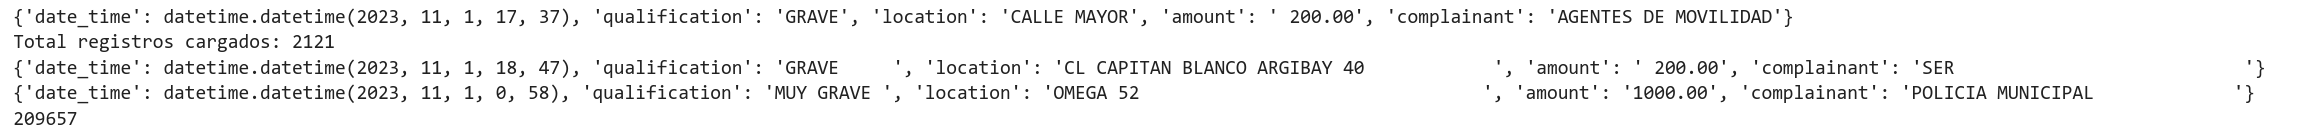

In [14]:
def check_parse_load_result():
    row = {'CALIFICACION': 'GRAVE', 'LUGAR': 'CALLE MAYOR', 'HORA': '17.37', 'IMP_BOL': ' 200.00', 'DENUNCIANTE': 'AGENTES DE MOVILIDAD', 'VEL_LIMITE':'   ', 'VEL_CIRCULA ': '   '}
    print(parse_row(row, 2023, 'nov'))
    row = {'CALIFICACION': 'GRAVE', 'LUGAR': 'CALLE MAYOR', 'HORA': '17.37', 'IMP_BOL': ' 200.00', 'DENUNCIANTE': 'AGENTES DE MOVILIDAD', 'VEL_LIMITE':'70   ', 'VEL_CIRCULA ': '85   '}
    print(parse_row(row, 2023, 'nov'))
    data = load_fines_data(2023, 'nov', TESTDATAFILE)
    print(f'Total registros cargados: {len(data)}')
    print(data[157])
    print(data[2046])
    data = load_fines_data(2023, 'nov')
    print(len(data))
check_parse_load_result()

{'date_time': datetime.datetime(2023, 11, 1, 17, 37), 'qualification': 'GRAVE', 'location': 'CALLE MAYOR', 'complainant': 'AGENTES DE MOVILIDAD', 'amount': 200, 'speed_limit': None, 'real_speed': None}
{'date_time': datetime.datetime(2023, 11, 1, 17, 37), 'qualification': 'GRAVE', 'location': 'CALLE MAYOR', 'complainant': 'AGENTES DE MOVILIDAD', 'amount': 200, 'speed_limit': 70, 'real_speed': 85}
Total registros cargados: 2121
{'date_time': datetime.datetime(2023, 11, 1, 18, 47), 'qualification': 'GRAVE', 'location': 'CL CAPITAN BLANCO ARGIBAY 40', 'complainant': 'SER', 'amount': 200, 'speed_limit': None, 'real_speed': None}
{'date_time': datetime.datetime(2023, 11, 1, 19, 44), 'qualification': 'GRAVE', 'location': 'M-30 XC K 19,06 CR4', 'complainant': 'POLICIA MUNICIPAL', 'amount': 100, 'speed_limit': 70, 'real_speed': 74}
209657


Comprueba tus doctests

In [15]:
doctest.run_docstring_examples(parse_row, globals(), verbose=True)

Finding tests in NoName
Trying:
    row = {'CALIFICACION': 'GRAVE  ', 'LUGAR': 'CALLE MAYOR  ', 'HORA': '17.37',
           'IMP_BOL': ' 200.00', 'DENUNCIANTE': 'SER  ',
           'VEL_LIMITE': '   ', 'VEL_CIRCULA ': '   '}
Expecting nothing
ok
Trying:
    parse_row(row, 2023, 'nov')
Expecting:
    {'date_time': datetime.datetime(2023, 11, 1, 17, 37), 'qualification': 'GRAVE', 'location': 'CALLE MAYOR', 'complainant': 'SER', 'amount': 200, 'speed_limit': None, 'real_speed': None}
ok


In [16]:
doctest.run_docstring_examples(load_fines_data, globals(), verbose=True)

Finding tests in NoName
Trying:
    len(load_fines_data(2023, 'nov', 'data_test.csv'))
Expecting:
    2121
ok


Comprueba la calidad del docstring

In [17]:
help(parse_row)

Help on function parse_row in module __main__:

parse_row(row: dict[str, str], year: int, month: str) -> __main__.TrafficFine
    Convierte una fila del CSV en un TrafficFine.
    
    Como el CSV no trae el día, se usa el día 1 del mes indicado junto con
    la HORA de la fila. Los textos se guardan sin espacios de relleno y las
    velocidades vacías como None.
    
    Args:
        row: Fila leída con csv.DictReader.
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').
    
    Returns:
        TrafficFine: La multa con los datos ya limpios.
    
    Raises:
        ValueError: Si `month` no está en MONTHS.
    
    Examples:
        >>> row = {'CALIFICACION': 'GRAVE  ', 'LUGAR': 'CALLE MAYOR  ', 'HORA': '17.37',
        ...        'IMP_BOL': ' 200.00', 'DENUNCIANTE': 'SER  ',
        ...        'VEL_LIMITE': '   ', 'VEL_CIRCULA ': '   '}
        >>> parse_row(row, 2023, 'nov')
        {'date_time': datetime.datetime(2023, 11, 1, 17

In [18]:
help(load_fines_data)

Help on function load_fines_data in module __main__:

load_fines_data(year: int, month: str, filepath: str | None = None) -> list[__main__.TrafficFine]
    Carga las multas de un mes como una lista de TrafficFine.
    
    Args:
        year: Año de los datos.
        month: Mes en inglés abreviado a 3 letras ('jan', ..., 'dec').
        filepath: Ruta del CSV. Si no se da, se usa 'yyyy_mm.csv'.
    
    Returns:
        list[TrafficFine]: Una multa por cada fila del fichero.
    
    Examples:
        >>> len(load_fines_data(2023, 'nov', 'data_test.csv'))
        2121



### Comprobación automática del código

In [19]:
testing.test_parse_row(parse_row)

test_parse_row OK


In [20]:
testing.test_parse_row_typehints(parse_row, TrafficFine)

check type hints OK


In [21]:
testing.test_docstring(parse_row)

docstring OK


In [22]:
testing.test_doctests(parse_row, globals())

doctests OK


In [23]:
testing.test_load_fines_data(load_fines_data)

test_load_fines_data OK


In [24]:
testing.test_load_fines_data_typehints(load_fines_data, TrafficFine)

check type hints OK


In [25]:
testing.test_docstring(load_fines_data)

docstring OK


In [26]:
testing.test_doctests(load_fines_data, globals())

doctests OK


A partir de aquí, los ejercicios 2 a 6 usan el conjunto de datos de prueba `data_test.csv` (noviembre de 2023), cargado una única vez en `TEST_DATA` con la función que acabas de implementar.

In [27]:
TEST_DATA = load_fines_data(2023, 'nov', TESTDATAFILE)
len(TEST_DATA)

2121

## Ejercicio 3: Filtrado por Calificación

Escribe una función con la cabecera `def count_by_qualification(data: list[TrafficFine], qualification: str) -> int:` que reciba el conjunto de datos en memoria y devuelva el número total de multas que coincidan con una calificación concreta (por ejemplo, `'GRAVE'`, `'LEVE'`, `'MUY GRAVE'`). Si `qualification` no está en la constante `QUALIFICATIONS`, la función debe lanzar un `ValueError`. Hay tener en cuenta que la calificación puede estar en minúsculas o maüusculas tanto en los datos como en el parámetro de la función.

In [28]:
def count_by_qualification(data: list[TrafficFine], qualification: str) -> int:
    """Cuenta las multas de una calificación, sin distinguir mayúsculas.

    Args:
        data: Multas cargadas en memoria.
        qualification: Calificación a contar ('LEVE', 'GRAVE' o 'MUY GRAVE').

    Returns:
        int: Número de multas con esa calificación.

    Raises:
        ValueError: Si la calificación no está en QUALIFICATIONS.

    Examples:
        >>> data = [{'qualification': 'GRAVE'}, {'qualification': 'leve'},
        ...         {'qualification': 'Grave'}]
        >>> count_by_qualification(data, 'grave')
        2
    """
    target = qualification.strip().upper()
    if target not in QUALIFICATIONS:
        raise ValueError(f"Calificación no válida: {qualification!r}")
    return sum(1 for fine in data if fine['qualification'].strip().upper() == target)

### Auto comprobación

La salida de la siguiente casilla debe mostrar el número de multas GRAVE, LEVE y MUY GRAVE de `TEST_DATA`.

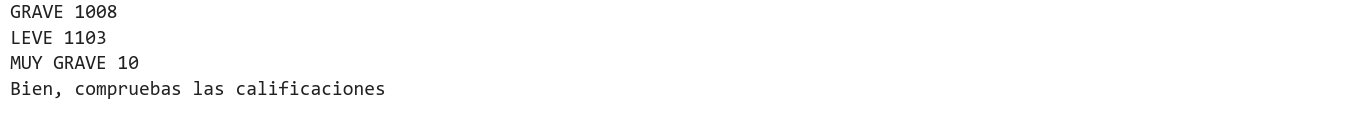

In [29]:
def check_count_by_qualification_result():
    for q in ('GRAVE', 'LEVE', 'MUY GRAVE'):
        print(q, count_by_qualification(TEST_DATA, q))
    try:
        count_by_qualification(TEST_DATA, 'gr')
    except:
        print('Bien, compruebas las calificaciones')
check_count_by_qualification_result()

GRAVE 1008
LEVE 1103
MUY GRAVE 10
Bien, compruebas las calificaciones


Comprueba tus doctests

In [30]:
doctest.run_docstring_examples(count_by_qualification, globals(), verbose=True)

Finding tests in NoName
Trying:
    data = [{'qualification': 'GRAVE'}, {'qualification': 'leve'},
            {'qualification': 'Grave'}]
Expecting nothing
ok
Trying:
    count_by_qualification(data, 'grave')
Expecting:
    2
ok


Comprueba la calidad del docstring

In [31]:
help(count_by_qualification)

Help on function count_by_qualification in module __main__:

count_by_qualification(data: list[__main__.TrafficFine], qualification: str) -> int
    Cuenta las multas de una calificación, sin distinguir mayúsculas.
    
    Args:
        data: Multas cargadas en memoria.
        qualification: Calificación a contar ('LEVE', 'GRAVE' o 'MUY GRAVE').
    
    Returns:
        int: Número de multas con esa calificación.
    
    Raises:
        ValueError: Si la calificación no está en QUALIFICATIONS.
    
    Examples:
        >>> data = [{'qualification': 'GRAVE'}, {'qualification': 'leve'},
        ...         {'qualification': 'Grave'}]
        >>> count_by_qualification(data, 'grave')
        2



### Comprobación automática del código

In [32]:
testing.test_count_by_qualification(count_by_qualification, TEST_DATA)

test_count_by_qualification OK


In [33]:
testing.test_count_by_qualification_typehints(count_by_qualification, TrafficFine)

check type hints OK


In [34]:
testing.test_docstring(count_by_qualification)

docstring OK


In [35]:
testing.test_doctests(count_by_qualification, globals())

doctests OK


## Ejercicio 4: Importe Total y Medio de las Multas

Escribe una función con la cabecera `def calculate_amount_stats(data: list[TrafficFine]) -> tuple[float, float]:` que reciba el conjunto de datos en memoria y devuelva una tupla con la suma total y la media de los importes de las multas (`amount`), redondeados a dos decimales.

In [36]:
def calculate_amount_stats(data: list[TrafficFine]) -> tuple[float, float]:
    """Calcula el importe total y el importe medio de las multas.

    Ambos valores se redondean a dos decimales. Si no hay multas, devuelve
    (0.0, 0.0) en lugar de dividir entre cero.

    Args:
        data: Multas cargadas en memoria.

    Returns:
        tuple[float, float]: (importe total, importe medio).

    Examples:
        >>> data = [{'amount': 200}, {'amount': 90}, {'amount': 60}]
        >>> calculate_amount_stats(data)
        (350.0, 116.67)
        >>> calculate_amount_stats([{'amount': 100}])
        (100.0, 100.0)
        >>> calculate_amount_stats([])
        (0.0, 0.0)
    """
    if not data:
        return 0.0, 0.0
    total = float(sum(fine['amount'] for fine in data))
    return round(total, 2), round(total / len(data), 2)


### Auto comprobación

La salida de la siguiente casilla debe mostrar el importe total y medio de `TEST_DATA`.

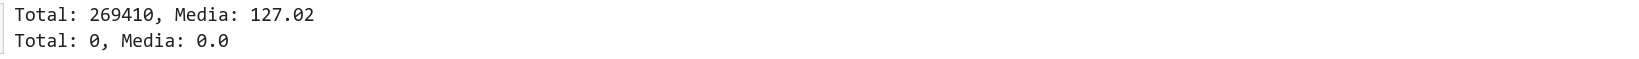

In [37]:
def check_calculate_amount_stats_result():
    total, average = calculate_amount_stats(TEST_DATA)
    print(f'Total: {total}, Media: {average}')
    total, average = calculate_amount_stats([])
    print(f'Total: {total}, Media: {average}')
check_calculate_amount_stats_result()

Total: 269410.0, Media: 127.02
Total: 0.0, Media: 0.0


Comprueba tus doctests

In [38]:
doctest.run_docstring_examples(calculate_amount_stats, globals(), verbose=True)

Finding tests in NoName
Trying:
    data = [{'amount': 200}, {'amount': 90}, {'amount': 60}]
Expecting nothing
ok
Trying:
    calculate_amount_stats(data)
Expecting:
    (350.0, 116.67)
ok
Trying:
    calculate_amount_stats([{'amount': 100}])
Expecting:
    (100.0, 100.0)
ok
Trying:
    calculate_amount_stats([])
Expecting:
    (0.0, 0.0)
ok


Comprueba la calidad del docstring

In [39]:
help(calculate_amount_stats)

Help on function calculate_amount_stats in module __main__:

calculate_amount_stats(data: list[__main__.TrafficFine]) -> tuple[float, float]
    Calcula el importe total y el importe medio de las multas.
    
    Ambos valores se redondean a dos decimales. Si no hay multas, devuelve
    (0.0, 0.0) en lugar de dividir entre cero.
    
    Args:
        data: Multas cargadas en memoria.
    
    Returns:
        tuple[float, float]: (importe total, importe medio).
    
    Examples:
        >>> data = [{'amount': 200}, {'amount': 90}, {'amount': 60}]
        >>> calculate_amount_stats(data)
        (350.0, 116.67)
        >>> calculate_amount_stats([{'amount': 100}])
        (100.0, 100.0)
        >>> calculate_amount_stats([])
        (0.0, 0.0)



### Comprobación automática del código

In [40]:
testing.test_calculate_amount_stats(calculate_amount_stats, TEST_DATA)

test_calculate_amount_stats OK


In [41]:
testing.test_calculate_amount_stats_typehints(calculate_amount_stats, TrafficFine)

check type hints OK


In [42]:
testing.test_docstring(calculate_amount_stats)

docstring OK


In [43]:
testing.test_doctests(calculate_amount_stats, globals())

doctests OK


## Ejercicio 5: Agregación por Tipo de Denunciante

Escribe una función con la cabecera `def count_by_complainant(data: list[TrafficFine]) -> dict[str, int]:` que reciba el conjunto de datos en memoria y devuelva un diccionario en el que cada clave sea una entidad denunciante (`complainant`) y su valor el número total de multas asociadas.

In [44]:
def count_by_complainant(data: list[TrafficFine]) -> dict[str, int]:
    """Cuenta las multas de cada entidad denunciante.

    Args:
        data: Multas cargadas en memoria.

    Returns:
        dict[str, int]: Para cada denunciante (`complainant`), el número de
        multas que ha puesto. Si no hay multas, devuelve un diccionario vacío.

    Examples:
        >>> data = [{'complainant': 'SER'}, {'complainant': 'POLICIA MUNICIPAL'},
        ...         {'complainant': 'SER'}]
        >>> count_by_complainant(data)
        {'SER': 2, 'POLICIA MUNICIPAL': 1}
        >>> count_by_complainant([])
        {}
    """
    counts: dict[str, int] = {}
    for fine in data:
        counts[fine['complainant']] = counts.get(fine['complainant'], 0) + 1
    return counts


### Auto comprobación

La salida de la siguiente casilla debe mostrar el recuento de multas por denunciante en `TEST_DATA`.

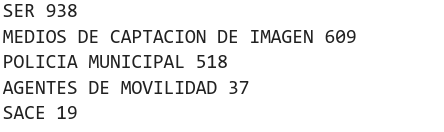

In [45]:
def check_count_by_complainant_result():
    result = count_by_complainant(TEST_DATA)
    for complainant, count in sorted(result.items(), key=lambda item: -item[1]):
        print(complainant, count)
check_count_by_complainant_result()

SER 938
MEDIOS DE CAPTACION DE IMAGEN 609
POLICIA MUNICIPAL 518
AGENTES DE MOVILIDAD 37
SACE 19


Comprueba tus doctests

In [46]:
doctest.run_docstring_examples(count_by_complainant, globals(), verbose=True)

Finding tests in NoName
Trying:
    data = [{'complainant': 'SER'}, {'complainant': 'POLICIA MUNICIPAL'},
            {'complainant': 'SER'}]
Expecting nothing
ok
Trying:
    count_by_complainant(data)
Expecting:
    {'SER': 2, 'POLICIA MUNICIPAL': 1}
ok
Trying:
    count_by_complainant([])
Expecting:
    {}
ok


Comprueba la calidad del docstring

In [47]:
help(count_by_complainant)

Help on function count_by_complainant in module __main__:

count_by_complainant(data: list[__main__.TrafficFine]) -> dict[str, int]
    Cuenta las multas de cada entidad denunciante.
    
    Args:
        data: Multas cargadas en memoria.
    
    Returns:
        dict[str, int]: Para cada denunciante (`complainant`), el número de
        multas que ha puesto. Si no hay multas, devuelve un diccionario vacío.
    
    Examples:
        >>> data = [{'complainant': 'SER'}, {'complainant': 'POLICIA MUNICIPAL'},
        ...         {'complainant': 'SER'}]
        >>> count_by_complainant(data)
        {'SER': 2, 'POLICIA MUNICIPAL': 1}
        >>> count_by_complainant([])
        {}



### Comprobación automática del código

In [48]:
testing.test_count_by_complainant(count_by_complainant, TEST_DATA)

test_count_by_complainant OK


In [49]:
testing.test_count_by_complainant_typehints(count_by_complainant, TrafficFine)

check type hints OK


In [50]:
testing.test_docstring(count_by_complainant)

docstring OK


In [51]:
testing.test_doctests(count_by_complainant, globals())

doctests OK


## Ejercicio 6: Lugar con Más Infracciones

Escribe una función con la cabecera `def top_location_fines(data: list[TrafficFine]) -> tuple[str, int]:` que reciba el conjunto de datos en memoria y devuelva una tupla con la calle/lugar (`location`) que tenga el mayor número de multas y su recuento total.

In [52]:
def top_location_fines(data: list[TrafficFine]) -> tuple[str, int]:
    """Devuelve el lugar con más multas y cuántas tiene ('', 0 si no hay datos).

    Args:
        data: Multas cargadas en memoria.

    Returns:
        tuple[str, int]: (lugar con más multas, número de multas).

    Examples:
        >>> data = [{'location': 'GRAN VIA'}, {'location': 'ALCALA'},
        ...         {'location': 'GRAN VIA'}]
        >>> top_location_fines(data)
        ('GRAN VIA', 2)
    """
    counts: dict[str, int] = {}
    for fine in data:
        counts[fine['location']] = counts.get(fine['location'], 0) + 1
    if not counts:
        return '', 0
    location = max(counts, key=counts.get)
    return location, counts[location]


### Auto comprobación

La salida de la siguiente casilla debe mostrar el lugar con más multas en `TEST_DATA`.

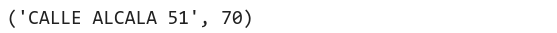

In [53]:
def check_top_location_fines_result():
    print(top_location_fines(TEST_DATA))
check_top_location_fines_result()

('CALLE ALCALA 51', 70)


Comprueba tus doctests

In [54]:
doctest.run_docstring_examples(top_location_fines, globals(), verbose=True)

Finding tests in NoName
Trying:
    data = [{'location': 'GRAN VIA'}, {'location': 'ALCALA'},
            {'location': 'GRAN VIA'}]
Expecting nothing
ok
Trying:
    top_location_fines(data)
Expecting:
    ('GRAN VIA', 2)
ok


Comprueba la calidad del docstring

In [55]:
help(top_location_fines)

Help on function top_location_fines in module __main__:

top_location_fines(data: list[__main__.TrafficFine]) -> tuple[str, int]
    Devuelve el lugar con más multas y cuántas tiene ('', 0 si no hay datos).
    
    Args:
        data: Multas cargadas en memoria.
    
    Returns:
        tuple[str, int]: (lugar con más multas, número de multas).
    
    Examples:
        >>> data = [{'location': 'GRAN VIA'}, {'location': 'ALCALA'},
        ...         {'location': 'GRAN VIA'}]
        >>> top_location_fines(data)
        ('GRAN VIA', 2)



### Comprobación automática del código

In [56]:
testing.test_top_location_fines(top_location_fines, TEST_DATA)

test_top_location_fines OK


In [57]:
testing.test_top_location_fines_typehints(top_location_fines, TrafficFine)

check type hints OK


In [58]:
testing.test_docstring(top_location_fines)

docstring OK


In [59]:
testing.test_doctests(top_location_fines, globals())

doctests OK


## Ejercicio 7: Datos por hora

Considera la definición 

```python
class Counter(TypedDict):
    count: int
    total: int
    mean: float
```


Escribe una función con la cabecera `def fines_by_hour(data: list[TrafficFine]) -> list[Countr]:` que reciba el conjunto de datos en memoria y devuelva una lista de 24 enteros representando con datos por hora del día (0-23), 
donde el índice `h` contiene un `Counter` con el número de multas registradas, el total y la media durante la hora `h` (por ejemplo, índice 13 = de 13:00 a 13:59).


In [60]:
def fines_by_hour(data: list[TrafficFine]) -> list[Counter]:
    """Agrupa las multas por hora del día (0-23).

    Args:
        data: Multas cargadas en memoria.

    Returns:
        list[Counter]: 24 Counter; el índice h tiene el número de multas,
        el importe total y el medio de la hora h (0 si no hay multas).

    Examples:
        >>> data = [{'date_time': datetime(2023, 11, 1, 13, 5), 'amount': 200},
        ...         {'date_time': datetime(2023, 11, 1, 13, 59), 'amount': 90}]
        >>> fines_by_hour(data)[13]
        {'count': 2, 'total': 290, 'mean': 145.0}
    """
    counters = [Counter(count=0, total=0, mean=0.0) for _ in range(24)]
    for fine in data:
        counter = counters[fine['date_time'].hour]
        counter['count'] += 1
        counter['total'] += fine['amount']
    for counter in counters:
        if counter['count']:
            counter['mean'] = round(counter['total'] / counter['count'], 2)
    return counters

### Auto comprobación

La salida de la siguiente casilla debe mostrar el histograma de multas por hora del día para `TEST_DATA`.

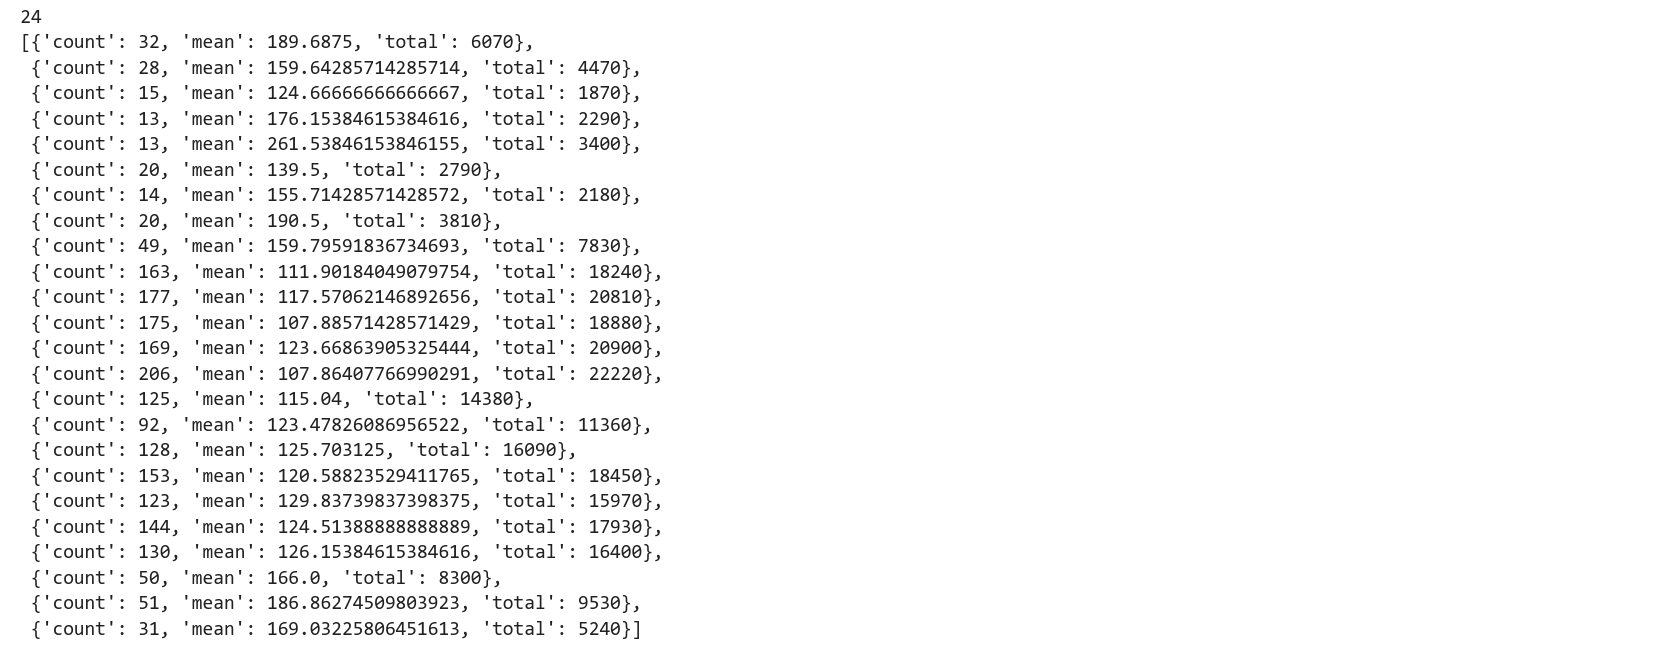

In [61]:
from pprint import pprint
def check_fines_by_hour_result():
    counters = fines_by_hour(TEST_DATA) 
    print(len(counters))
    pprint(counters)
check_fines_by_hour_result()

24
[{'count': 32, 'mean': 189.69, 'total': 6070},
 {'count': 28, 'mean': 159.64, 'total': 4470},
 {'count': 15, 'mean': 124.67, 'total': 1870},
 {'count': 13, 'mean': 176.15, 'total': 2290},
 {'count': 13, 'mean': 261.54, 'total': 3400},
 {'count': 20, 'mean': 139.5, 'total': 2790},
 {'count': 14, 'mean': 155.71, 'total': 2180},
 {'count': 20, 'mean': 190.5, 'total': 3810},
 {'count': 49, 'mean': 159.8, 'total': 7830},
 {'count': 163, 'mean': 111.9, 'total': 18240},
 {'count': 177, 'mean': 117.57, 'total': 20810},
 {'count': 175, 'mean': 107.89, 'total': 18880},
 {'count': 169, 'mean': 123.67, 'total': 20900},
 {'count': 206, 'mean': 107.86, 'total': 22220},
 {'count': 125, 'mean': 115.04, 'total': 14380},
 {'count': 92, 'mean': 123.48, 'total': 11360},
 {'count': 128, 'mean': 125.7, 'total': 16090},
 {'count': 153, 'mean': 120.59, 'total': 18450},
 {'count': 123, 'mean': 129.84, 'total': 15970},
 {'count': 144, 'mean': 124.51, 'total': 17930},
 {'count': 130, 'mean': 126.15, 'total': 

Comprueba tus doctests

In [62]:
doctest.run_docstring_examples(fines_by_hour, globals(), verbose=True)

Finding tests in NoName
Trying:
    data = [{'date_time': datetime(2023, 11, 1, 13, 5), 'amount': 200},
            {'date_time': datetime(2023, 11, 1, 13, 59), 'amount': 90}]
Expecting nothing
ok
Trying:
    fines_by_hour(data)[13]
Expecting:
    {'count': 2, 'total': 290, 'mean': 145.0}
ok


Comprueba la calidad del docstring

In [63]:
help(fines_by_hour)

Help on function fines_by_hour in module __main__:

fines_by_hour(data: list[__main__.TrafficFine]) -> list[__main__.Counter]
    Agrupa las multas por hora del día (0-23).
    
    Args:
        data: Multas cargadas en memoria.
    
    Returns:
        list[Counter]: 24 Counter; el índice h tiene el número de multas,
        el importe total y el medio de la hora h (0 si no hay multas).
    
    Examples:
        >>> data = [{'date_time': datetime(2023, 11, 1, 13, 5), 'amount': 200},
        ...         {'date_time': datetime(2023, 11, 1, 13, 59), 'amount': 90}]
        >>> fines_by_hour(data)[13]
        {'count': 2, 'total': 290, 'mean': 145.0}



### Comprobación automática del código

In [64]:
testing.test_fines_by_hour(fines_by_hour, TEST_DATA)

test_fines_by_hour OK


In [65]:
testing.test_fines_by_hour_typehints(fines_by_hour, TrafficFine, Counter)

check type hints OK


In [66]:
testing.test_docstring(fines_by_hour)

docstring OK


In [67]:
testing.test_doctests(fines_by_hour, globals())

doctests OK


## Ejercicio 8: Mínimo Exceso de Velocidad

Algunas multas (las de exceso de velocidad) tienen registrados `speed_limit` y `real_speed`. Escribe una función con la cabecera `def min_speed_excess(data: list[TrafficFine]) -> int:` que reciba el conjunto de datos en memoria y devuelva el **mínimo** exceso de velocidad (`real_speed - speed_limit`) entre las multas que tienen ambos valores registrados.

Si ninguna multa tiene ambos valores (`speed_limit` y `real_speed`) registrados, la función debe devolver `0`.

In [68]:
def min_speed_excess(data: list[TrafficFine]) -> int:
    """Devuelve el mínimo exceso de velocidad (real_speed - speed_limit).

    Solo cuenta las multas con las dos velocidades; si no hay ninguna, 0.

    Args:
        data: Multas cargadas en memoria.

    Returns:
        int: Mínimo exceso de velocidad en km/h.

    Examples:
        >>> data = [{'speed_limit': 70, 'real_speed': 88},
        ...         {'speed_limit': 50, 'real_speed': 61},
        ...         {'speed_limit': None, 'real_speed': None}]
        >>> min_speed_excess(data)
        11
    """
    excesses = [fine['real_speed'] - fine['speed_limit']
                for fine in data
                if fine['speed_limit'] is not None and fine['real_speed'] is not None]
    return min(excesses, default=0)

### Auto comprobación

La salida de la siguiente casilla debe mostrar el mínimo exceso de velocidad en `TEST_DATA`.

In [69]:
def check_min_speed_excess_result():
    print(min_speed_excess(TEST_DATA))
check_min_speed_excess_result()

3


Comprueba tus doctests

In [70]:
doctest.run_docstring_examples(min_speed_excess, globals(), verbose=True)

Finding tests in NoName
Trying:
    data = [{'speed_limit': 70, 'real_speed': 88},
            {'speed_limit': 50, 'real_speed': 61},
            {'speed_limit': None, 'real_speed': None}]
Expecting nothing
ok
Trying:
    min_speed_excess(data)
Expecting:
    11
ok


Comprueba la calidad del docstring

In [71]:
help(min_speed_excess)

Help on function min_speed_excess in module __main__:

min_speed_excess(data: list[__main__.TrafficFine]) -> int
    Devuelve el mínimo exceso de velocidad (real_speed - speed_limit).
    
    Solo cuenta las multas con las dos velocidades; si no hay ninguna, 0.
    
    Args:
        data: Multas cargadas en memoria.
    
    Returns:
        int: Mínimo exceso de velocidad en km/h.
    
    Examples:
        >>> data = [{'speed_limit': 70, 'real_speed': 88},
        ...         {'speed_limit': 50, 'real_speed': 61},
        ...         {'speed_limit': None, 'real_speed': None}]
        >>> min_speed_excess(data)
        11



### Comprobación automática del código

In [72]:
testing.test_min_speed_excess(min_speed_excess, TEST_DATA)

test_min_speed_excess OK


In [73]:
testing.test_min_speed_excess_typehints(min_speed_excess, TrafficFine)

check type hints OK


In [74]:
testing.test_docstring(min_speed_excess)

docstring OK


In [75]:
testing.test_doctests(min_speed_excess, globals())

doctests OK


## Comprobación final antes de entregar

**Guarda el cuaderno ahora (Ctrl+S / Cmd+S)** y, después, ejecuta la siguiente casilla. Comprueba que no haya identificadores de celda duplicados (algo que suele pasar al copiar una celda de solución o de test en vez de escribir en la tuya propia).

In [76]:
testing.check_duplicated_ids('E1_analisis_fichero.ipynb')

OK. No se han encontrado grade_id duplicados.
